# Industry-Style Agentic RAG with LangGraph

## Why this is industry-style

A simple RAG system searches only the private knowledge base.

An industry-style Agentic RAG system should do this:

```text
Question
  ↓
Search private knowledge base first
  ↓
Grade the private evidence
  ↓
If private evidence is good → answer from KB
  ↓
If private evidence is weak → search the web
  ↓
Grade web evidence
  ↓
Generate a grounded answer with source type
```

This design is useful because private documents may be incomplete or outdated.

## 1. Install Dependencies

## 2. Configure API Keys

In [ ]:
import os
from getpass import getpass

try:
    from dotenv import load_dotenv
    load_dotenv()
except EnvironmentError:
    raise

_GROQ_API_KEY = os.getenv("GROQ_API_KEY")
_GROQ_MODEL = os.getenv("GROQ_MODEL")
_TAVILY_API_KEY = os.getenv("TAVILY_API_KEY")
_PINECONE_API_KEY = os.getenv("PINECONE_API_KEY")
_GEMINI_API_KEY = os.getenv("GEMINI_API_KEY")
_LANGSMITH_API_KEY = os.getenv("LANGSMITH_API_KEY")
_HUGGINGFACE_API_KEY = os.getenv("HUGGINGFACE_API_KEY")
_EMBEDDING_MODEL_NAME = os.getenv("EMBEDDING_MODEL_NAME")
_RERANKING_MODEL_NAME=os.getenv("RERANKING_MODEL_NAME")
_PINECONE_INDEX_NAME = os.getenv("PINECONE_INDEX_NAME")
_PINECONE_INDEX_NAMESPACE = os.getenv("PINECONE_INDEX_NAMESPACE")
_MAX_RETRIES= os.getenv("MAX_RETRIES")

missing_api_key_list = []
if not _GROQ_API_KEY:
    missing_api_key_list.append("GROQ_API_KEY")
if not _GROQ_MODEL:
    missing_api_key_list.append("GROQ_MODEL")
if not _TAVILY_API_KEY:
    missing_api_key_list.append("TAVILY_API_KEY")
if not _PINECONE_API_KEY:
    missing_api_key_list.append("PINECONE_API_KEY")
if not _LANGSMITH_API_KEY:
    missing_api_key_list.append("LANGSMITH_API_KEY")
if not _GEMINI_API_KEY:
    missing_api_key_list.append("GEMINI_API_KEY")
if not _HUGGINGFACE_API_KEY:
    missing_api_key_list.append("HUGGINGFACE_API_KEY")
if not _EMBEDDING_MODEL_NAME:
    missing_api_key_list.append("EMBEDDING_MODEL_NAME")
if not _RERANKING_MODEL_NAME:
    missing_api_key_list.append("RERANKING_MODEL_NAME")   
if not _PINECONE_INDEX_NAME:
    missing_api_key_list.append("PINECONE_INDEX_NAME")
if not _PINECONE_INDEX_NAMESPACE:
    missing_api_key_list.append("PINECONE_INDEX_NAMESPACE")
if not _MAX_RETRIES:
    missing_api_key_list.append("MAX_RETRIES")    

if missing_api_key_list is None:
    print("missing_api_key_list: ", missing_api_key_list)
else:
    print("No missing_api_keys")

python-dotenv could not parse statement starting at line 15
python-dotenv could not parse statement starting at line 17
python-dotenv could not parse statement starting at line 18
python-dotenv could not parse statement starting at line 24


No missing_api_keys


## 3. Load Documents

create private knowledge base from a real web document:

`https://docs.langchain.com/oss/python/langgraph/agentic-rag`


The web fallback is separate. That means:

- First source: indexed LangGraph documentation page/private knowledge base
- Fallback source: live web search through Tavily

In [438]:
from langchain_community.document_loaders import WebBaseLoader
url= "https://docs.langchain.com/oss/python/langgraph/agentic-rag"
loader= WebBaseLoader(
    web_path=url,
)
raw_docs=loader.load()
print(raw_docs)
print("Length of data:",len(raw_docs))
print("source: ",raw_docs[0].metadata.get("source"))
print("\nPreview:")
print(raw_docs[0].page_content[:1500])

[Document(metadata={'source': 'https://docs.langchain.com/oss/python/langgraph/agentic-rag', 'title': 'Build a custom RAG agent with LangGraph - Docs by LangChain', 'description': 'Build a custom retrieval agent with LangGraph that decides when to search a vector store or respond directly.', 'language': 'en'}, page_content='\n\n\n\n\nBuild a custom RAG agent with LangGraph - Docs by LangChain\n\n\n\n\n\n\n\n\n\nDocumentation IndexFetch the complete documentation index at: /llms.txtUse this file to discover all available pages before exploring further.Skip to main contentDocs by LangChain home pageBuildSearch...⌘KAsk AIGitHubTry LangSmithTry LangSmithSearch...NavigationLangGraphBuild a custom RAG agent with LangGraphOverviewManaged Deep AgentsDeep AgentsLangChainLangGraphOpenWikiIntegrationsLearnReferenceContributePythonLearnTutorialsDeep AgentsData AnalysisDeep ResearchContent BuilderRAGLangChainDeep AgentSemantic searchSQL agentVoice agentMulti-agentSubagents: Personal assistantHandof

## 4. Split the document into chunks

In [439]:
from langchain_text_splitters import RecursiveCharacterTextSplitter
splitter= RecursiveCharacterTextSplitter(
    chunk_size=1000,
    chunk_overlap=150,
    add_start_index=True
)

chunks= splitter.split_documents(raw_docs)
print("No of chunks: ",len(chunks))
print("\nChunk Overview:\n")
print(chunks[0].page_content[:900])

No of chunks:  29

Chunk Overview:

Build a custom RAG agent with LangGraph - Docs by LangChain


## 5.Create Free Local Embeddings

In [440]:
from langchain_huggingface import HuggingFaceEmbeddings
embedding_model= HuggingFaceEmbeddings(
    model_name=_EMBEDDING_MODEL_NAME,
    encode_kwargs={"normalize_embeddings": True},
)
sample_vector= embedding_model.embed_query("What is AI")
print(sample_vector)
print("Dimension of sample_vector: ", len(sample_vector))

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

[-0.028200604021549225, -0.01767549104988575, 0.011596094816923141, 0.016015753149986267, 0.04570591449737549, -0.016152163967490196, 0.06501337140798569, 0.03180595859885216, 0.02927895076572895, 0.05825495719909668, -0.04292963445186615, -0.0031239588279277086, 0.009426325559616089, -0.04228343069553375, -0.044077593833208084, 0.07152608036994934, -0.024430735036730766, -0.04126305133104324, -0.07005303353071213, -0.0744962990283966, -0.01328513864427805, 0.008898185566067696, -0.05688978731632233, -0.07097279280424118, -0.03665560483932495, 0.09129755944013596, 0.028841955587267876, -0.07827775180339813, -0.010502164252102375, -0.018226725980639458, 0.017554515972733498, -0.06115095689892769, 0.08683191239833832, 0.015249382704496384, -0.04012492299079895, 0.026451347395777702, -0.04383980482816696, -0.048619404435157776, 0.0956171303987503, -0.02186715044081211, -0.014999940991401672, -0.040611714124679565, 0.01712801866233349, -0.06966650485992432, 0.10470202565193176, 0.124466702

In [441]:
def embedding_model_dimension(embedding_model):
    sample_vector= embedding_model.embed_query("What is AI?")
    dimension= len(sample_vector)
    return dimension


print("embedding_model_dimension: ",embedding_model_dimension(embedding_model))

embedding_model_dimension:  384


## 6. creating the pinecone vector database

The embedding model used in this notebook produces **384-dimensional vectors**, so the Pinecone index must use dimension `384`.

# steps:
# 1. create pinecone vector store or index using Pinecone class
# 2. send the documents to pinecone index using lagchain_pinecone class
# 3. make the retriever

In [ ]:
from pinecone import Pinecone,ServerlessSpec
from langchain_pinecone import PineconeVectorStore
import time

# 1. create pinecone vector store or index using Pinecone class
pinecone_object= Pinecone(
    api_key=_PINECONE_API_KEY,
)
# creating the pinecone index if it doesn't exist
existing_indexes= [index_info["name"] for index_info in pinecone_object.list_indexes()]
print(existing_indexes)

if _PINECONE_INDEX_NAME not in existing_indexes:
    pinecone_object.create_index(
        name=_PINECONE_INDEX_NAME,
        dimension=embedding_model_dimention(embedding_model),
        metric='cosine',
        spec=ServerlessSpec(cloud='aws',region='us-east-1')
    )
# wait until the index is prepared in pinecone
while not pinecone_object.describe_index(name=_PINECONE_INDEX_NAME).status['ready']:
    time.wait(1)
print("pinecone index is ready: ",_PINECONE_INDEX_NAME)    

# 2. send the documents to pinecone index using lagchain_pinecone class and making vector store
vector_store= PineconeVectorStore.from_documents(
    documents=chunks,
    embedding=embedding_model,
    index_name=_PINECONE_INDEX_NAME,
    namespace=_PINECONE_INDEX_NAMESPACE
)

# # 3. make the retriever
# retriever = vector_store.as_retriever(
#     search_kwargs={
#         "k": 10,
#         "namespace":_PINECONE_INDEX_NAMESPACE
#     }
# )
# print('Pinecone vector database and its retriever is ready.')

['it-support-agentic-rag-indexname']
pinecone index is ready:  it-support-agentic-rag-indexname
Pinecone vector database and its retriever is ready.


# 7.Loading the existing index

In [ ]:
from pinecone import Pinecone
from langchain_pinecone import PineconeVectorStore

# making the pinecone object
pinecone_object= Pinecone(api_key=_PINECONE_API_KEY)

# # loading pinecone index
index = pinecone_object.Index(_PINECONE_INDEX_NAME)

# connecting the vector store using pinecone 
vector_store= PineconeVectorStore(
    index=index,
    embedding=embedding_model,
    namespace=_PINECONE_INDEX_NAMESPACE
)

Existing Index:  it-support-agentic-rag-indexname


# making retriever

In [ ]:

# making retriver
retriever= vector_store.as_retriever(
    search_kwargs={"k":10,'namespace':_PINECONE_INDEX_NAMESPACE}
)

print("Existing Index: ",_PINECONE_INDEX_NAME)


# 8. testing the private KB along with reranker

In [ ]:
from sentence_transformers import CrossEncoder

query="what is langchain?"
# step-1: retrieve documents
kb_docs= retriever.invoke(query)
print(kb_docs)

# step-2: create query document pairs




for i, doc in enumerate(kb_docs):
    print(f"\n----KB DOCS{i+1}---")
    print("source: ", doc.metadata.get('source'))
    print("content: ", doc.page_content[:500])
    print(i)


[Document(id='1ae443e7-fa37-4dc4-8ff4-6e5eb7f1c7a5', metadata={'description': 'Build a custom retrieval agent with LangGraph that decides when to search a vector store or respond directly.', 'language': 'en', 'source': 'https://docs.langchain.com/oss/python/langgraph/agentic-rag', 'start_index': 5.0, 'title': 'Build a custom RAG agent with LangGraph - Docs by LangChain'}, page_content='Build a custom RAG agent with LangGraph - Docs by LangChain'), Document(id='a555b290-d7b6-4d7d-9ada-6a4d8dfaf603', metadata={'description': 'Build a custom retrieval agent with LangGraph that decides when to search a vector store or respond directly.', 'language': 'en', 'source': 'https://docs.langchain.com/oss/python/langgraph/agentic-rag', 'start_index': 5.0, 'title': 'Build a custom RAG agent with LangGraph - Docs by LangChain'}, page_content='Build a custom RAG agent with LangGraph - Docs by LangChain'), Document(id='e6793958-a53a-4dd3-816d-41e07e14e9ad', metadata={'description': 'Build a custom retr

# 8. initializing groq LLM

In [445]:
from langchain_groq import ChatGroq
llm= ChatGroq(
    model=_GROQ_MODEL,
    temperature=0
)
query= llm.invoke("What is langchain in 10 words?")
print(query.content)

LangChain is a framework for building AI‑powered language applications efficiently.


# 9. Initiate Tavily websearch

Tavily will be used only when the private knowledge base is insufficient.

This is important because we do not want to send every private/company question to the public web.

In [ ]:
from langchain_tavily import TavilySearch

web_search= TavilySearch(
    max_results= 5,
    topic= 'general',
    include_answer= True,
)

print("Tavily web_search tool is ready")

Tavily web_search tool is ready


In [447]:
web_search.invoke("recent AI news?")

{'query': 'recent AI news?',
 'follow_up_questions': None,
 'answer': "Recent AI news highlights several significant developments. The Wall Street Journal reports on CNTXT AI expanding into Silicon Valley and a DHS order to remove DeepSeek Technology from federal systems. The WSJ also covers Tesla's AI-driven advancements and a satellite launch featuring AI chips. Anthropic introduces its new AI agent, Claude Duet, while cybersecurity threats and new AI models from companies like Ideogram and ElevenLabs are also noted. The FTC has opened an investigation into Anthropic and OpenAI. These updates underscore the rapid evolution and diverse applications of artificial intelligence today.",
 'images': [],
 'results': [{'url': 'https://www.yeschat.ai/gpts-9t557fXdeRL-Recent-AI-News',
   'title': 'Recent AI News-Free, Customized AI Updates',
   'score': 0.9358233,
   'content': "Recent AI News is designed as an expert GPT aimed at keeping users engaged and informed about the latest development

# 10. Defining structured Decisions and Langgraph state

We need reliable yes/no or route outputs from the LLM.

Structured outputs help avoid parsing messy natural language.

In [448]:
from typing import List, Literal, TypedDict
from pydantic import BaseModel,Field
from langchain_core.documents import Document

class DecisionRoute(BaseModel):
    route: Literal["kb",'direct']= Field(
        description="Use 'kb' when we need to answer using Agentic RAG; Use 'direct' for simple questions where 'kb' is not required."
    )

class GradingAnswer(BaseModel):
    grade: Literal['good','weak']= Field(
        description="grade the answer as 'good' if the evidence is enough to answer the query, otherwise return 'weak'."
    )

class AgentState(TypedDict):
    query: str
    source_used:str
    current_query: str

    kb_docs: List[Document]
    web_results:str

    kb_grade:str
    web_grade:str
    
    answer: str   

    retry_count:int 

# Nodes

## 11. Node 1

The router decides:

- `kb`: use private knowledge base
- `direct`: answer without retrieval

In a real company assistant, this step may also route between many sources:
HR docs, finance docs, product docs, SQL database, web search, etc.

In [449]:
router_llm= llm.with_structured_output(DecisionRoute,method='json_schema')

def route_question(state:AgentState):
    query= state["query"]

    decision= router_llm.invoke(f'''
    you are a router for Agentic Rag assistant.

    route to 'kb' if the user asks about:
    - Agentic RAG
    - LangGraph Agentic RAG workflow
    - retrieval grading
    - query rewriting
    - RAG architecture
    - retriever tools
    - web fallback in RAG

    route to 'direct' only for greetings, thanks or very simple conversations.

    query:
    {query}

    Return your response as valid JSON.
    Example:
    {{"route": "kb"}}
    ''')

    return {
        'query':query,
        'source_used': decision.route
    }

# function for conditional edges
def route_after_routing(state: AgentState)->Literal['retriever_kb','direct_answer']:
    if state['source_used']=='kb':
        return 'retriever_kb'
    return 'direct_answer'

# 12. Node-2 : Retrive from the private KB

In [450]:
def retriever_kb(state:AgentState)->dict:
    query= state["current_query"]
    chunks= retriever.invoke(input=query)

    print(f"[kb_retriever] query:{query}")
    print(f"[kb_retriever] retrieved:{len(chunks)} chunks")

    return {
        "kb_docs":chunks,
    }

# 13. Node 3: Grade Private KB Evidence

This is the key step that decides whether we can answer from the private KB or need web fallback.

In [ ]:
kb_grader_llm = llm.with_structured_output(
    schema=GradingAnswer, method="json_schema"
)

def grade_kb_evidence(state: AgentState):
  query = state["query"]
  context = "\n\n".join(
      f"source: {doc.metadata.get('source')} \n {doc.page_content}"
      for doc in state["kb_docs"]
  )

  grade = kb_grader_llm.invoke(f""" 
        You are an evidence grader.
        Query: {query},
        Private KB evidence: {context}

        If the private kb evidence can answer the query, return "good".
        Return "weak" if it can not answer the query or is incomplete.

        Return response as valid JSON matching the schema.
        Example:
        {{"grade": "good"}}
        """)

  print(f"[kb_grader] : {grade.grade}")

  return {"kb_grade": grade.grade}


def decide_after_kb_grade(state: AgentState):
  if state["kb_grade"] == "good":
    return "generate_from_kb"
  return "search_web"

## 14. Node 4 — Tavily Web Search Fallback

This node runs only when the private KB evidence is weak.

We search the web using the original question, or the current rewritten query if a rewrite already happened.

In [ ]:
def search_web(state:AgentState):
    query= state['current_query']
    # print(f"Tavily query: {query}")
    
    web_output= web_search.invoke(query)
    
    # Tavily can return dict/list structures depending on package version.
    # Convert it into readable text for grading and generation.
    
    if isinstance(web_output,dict):
        answer= web_output.get('answer',"")
        results= web_output.get('results',[])
        lines=[]
        for item in results:
            url= item.get('url','')
            title= item.get('title','')
            content= item.get('content','')
            lines.append(f"Title:{title}\nURL:{url}\ncontent:{content}")
        web_text= '\n\n'.join(i for i in lines)    
    else:
        web_text= str(web_output)   
        
    print("[Tavily Search] Result characters:", len(web_text))    
    
    return {"web_results":web_text, "source_used":'web'}     

## 15. Node 5 — Grade Web Evidence

In [453]:
web_grader_llm= llm.with_structured_output(schema=GradingAnswer,method="json_schema")

def grade_web_evidence(state:AgentState):
    query=state["query"]
    web_results= state["web_results"]
    
    grade= web_grader_llm.invoke(f""" 
    you are a web result grader
    query:{query}
    web_results: {web_results}
    
    if the web_results is enough to answer the query, return "good",
    else return "weak".
    
    Return your response as valid JSON.
    Example:
    {{"grade": "good"}}
    """)
    print("[Web Grader]", grade.grade)

    return {"web_grade": grade.grade}

MAX_RETRIES= int(_MAX_RETRIES)

def decide_after_web_grade(state: AgentState)-> Literal["generate_from_web",'rewrite_query','answer_insufficient']:
    if state["web_grade"]=='good':
        return "generate_from_web"
    if state["retry_count"] < MAX_RETRIES:
        return 'rewrite_query'
    
    return 'answer_insufficient'

## 16. Node 6 — Rewrite the Query

If both KB and web evidence are weak, we rewrite once and then try the KB again.

Why back to KB first?

Because the rewritten query may help retrieve better private evidence before relying on web search again.

In [ ]:
def rewrite_query(state:AgentState):
    query= state['query']
    retry_count= state['retry_count']+1
    
    rewritten= llm.invoke(f'''
    rewrite the query for better retrieval and web search.
    Rules:
    - Preserve original intent 
    - Make it specific and search friendly   
    - Do not answer
    - Return only the rewritten query
    
    Original query:
    {query}                  
    ''')
    
    # print(f"[rewritten_query]: {rewritten}")
    
    return {
        'current_query':rewritten.content,
        'retry_count': retry_count
    }

## 17. Node 7 — Generate from Private KB

In [455]:
def generate_from_kb(state:AgentState):
    query= state["query"]
    context= "\n\n".join(
        f"[kb_source: {doc.metadata.get('source')}]\n {doc.page_content}"
        for doc in state["kb_docs"]
    )
    
    answer= llm.invoke(f'''
    you are a technical instructor
    Answer only from the provided Private KB context
    
    Rules:
    - Beginner friendly explanation
    - Do not invent unsupported details
    - Mention that the answer is based on the Private KB
    - Include source type : Private KB
    
    query: {query}
    Private KB context: {context}
    ''')
    
    return {
        'answer': answer.content,
        'source_used': 'private_kb'
    }

# 18. Node-8: Generate from web search

In [456]:
def generate_from_web(state:AgentState):
    query= state["query"]
    web_results= state["web_results"]
    
    answer = llm.invoke(f"""
    you are a technical instructor
    Private KB is insufficient so web search is used
    Answer using only the web search context
    
    Rules:
    - Beginner-friendly explanation
    - Do not invent unsupported details
    - Mention that the answer is based on Tavily web result
    - If URLs are present in the context, include the most useful URLs 
    
    query: {query}
    web search context: {web_results}
    """)
    
    return {
        "answer":answer.content,
        "source_used":'web_search'
    }

# 19. Node-9: Direct answer

In [457]:
def direct_answer(state:AgentState):
    query=state["query"]
    answer= llm.invoke(f""" 
    Respond briefly and naturally
    Message: {query}
    """)
    return {'answer':answer.content,  "source_used":'direct'}

# 20. Node-10: Insufficient evident answer

In [458]:
def answer_insufficient(state:AgentState):
    answer= (
        "Sorry.I could not find enough evidence to answer from private knowledge base or web search."
        "Please specify more specific documents or rephrase the question "
    )
    return{
        "answer":answer,
        "source_used":"insufficient_evidence"
    }

# 21. Langgraph workflow

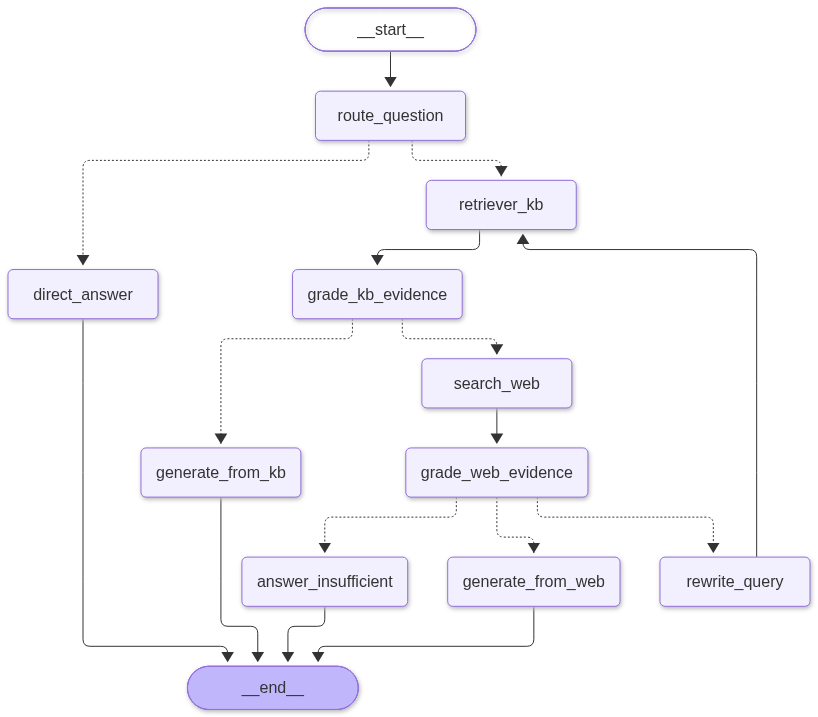

In [459]:
from langgraph.graph import StateGraph,START,END

workflow= StateGraph(state_schema=AgentState)

# adding nodes
workflow.add_node('route_question',route_question)
workflow.add_node('retriever_kb',retriever_kb)
workflow.add_node('grade_kb_evidence',grade_kb_evidence)
workflow.add_node('search_web',search_web)
workflow.add_node('grade_web_evidence',grade_web_evidence)
workflow.add_node('rewrite_query',rewrite_query)
workflow.add_node('generate_from_kb',generate_from_kb)
workflow.add_node('generate_from_web',generate_from_web)
workflow.add_node('direct_answer',direct_answer)
workflow.add_node('answer_insufficient',answer_insufficient)

# adding edges
workflow.add_edge(START,'route_question')
workflow.add_conditional_edges(
    'route_question',
    route_after_routing,
    {'retriever_kb':'retriever_kb',
     'direct_answer':'direct_answer'}
)

workflow.add_edge('retriever_kb','grade_kb_evidence')
workflow.add_conditional_edges(
    'grade_kb_evidence',
    decide_after_kb_grade,
    {'generate_from_kb':'generate_from_kb',
     'search_web':'search_web'
    }
)

workflow.add_edge('search_web','grade_web_evidence')
workflow.add_conditional_edges(
    'grade_web_evidence',
    decide_after_web_grade,
    {
        'generate_from_web':'generate_from_web',
        'rewrite_query':'rewrite_query',
        'answer_insufficient':'answer_insufficient'
    }
)

workflow.add_edge('rewrite_query','retriever_kb')

workflow.add_edge('generate_from_kb',END)
workflow.add_edge('generate_from_web',END)
workflow.add_edge('direct_answer',END)
workflow.add_edge('direct_answer',END)

app= workflow.compile()

app


# 23. Helper function

In [460]:
def ask_agent(query:str):
    initial_state: AgentState={
    'query': query,
    'source_used':'',
    'current_query': query,
    'kb_docs': [],
    'web_results':'',
    'kb_grade':'',
    'web_grade':'',
    'answer': '' ,  
    'retry_count':0,
    }
    
    result= app.invoke(initial_state)
    
    print("\n"+'='*90)
    print('query: ',query)
    print('source_used:',result['source_used'])
    print('answer: ',result['answer'])
    print("\n"+'='*90)
    
    return result

## 24. Demo 1 — Answer from Private KB

In [461]:
result = ask_agent(
    "In Agentic RAG, what happens when retrieved documents are not relevant?"
)

[kb_retriever] query:In Agentic RAG, what happens when retrieved documents are not relevant?
[kb_retriever] retrieved:5 chunks
[kb_grader] : weak
Tavily query: In Agentic RAG, what happens when retrieved documents are not relevant?
[Tavily Search] Result characters: 7289
[Web Grader] good

query:  In Agentic RAG, what happens when retrieved documents are not relevant?
source_used: web_search
answer:  **What happens when the documents the agent pulls in aren’t useful?**

In an *Agentic RAG* system the LLM is not just a one‑shot generator.  
It runs in a loop that checks whether the information it has found actually
answers the user’s question. If the retrieved documents are irrelevant or
missing key facts, the agent does the following (based on the Tavily‑searched
sources):

| Step | What the agent does | Why it matters |
|------|---------------------|----------------|
| **Gap identification** | The agent reviews the draft answer and looks for missing pieces (e.g., “I have the medicatio

## 25. Demo 2 — Web Search Fallback

In [462]:
result = ask_agent(
    "What is Tavily Search and why is it useful for AI agents and RAG workflows?"
)

[kb_retriever] query:What is Tavily Search and why is it useful for AI agents and RAG workflows?
[kb_retriever] retrieved:5 chunks
[kb_grader] : weak
Tavily query: What is Tavily Search and why is it useful for AI agents and RAG workflows?
[Tavily Search] Result characters: 6452
[Web Grader] good

query:  What is Tavily Search and why is it useful for AI agents and RAG workflows?
source_used: web_search
answer:  **What is Tavily Search?**  
Tavily Search is a web‑access API that is built *specifically* for large language models (LLMs) and retrieval‑augmented generation (RAG) systems. Instead of giving a list of links for a human to click, it returns short, AI‑optimized snippets that an LLM can read and reason over directly. It also offers endpoints to extract clean text from URLs and to crawl entire sites, all in formats that fit neatly into an agent’s reasoning loop.  

**Why is it useful for AI agents and RAG workflows?**  
1. **Live, up‑to‑date information** – Agents can ask Tavily 

## 26. Demo 3 — Direct Answer

In [463]:
result = ask_agent("Hello, how are you?")


query:  Hello, how are you?
source_used: direct
answer:  Hi! I'm doing well, thanks. How about you?



## 27. Demo 4 — Ask a Current / External Question

In [ ]:
result = ask_agent(
    "What is the current LangChain Tavily package used for Python web search integration?"
)

[kb_retriever] query:What is the current LangChain Tavily package used for Python web search integration?
[kb_retriever] retrieved:5 chunks
[kb_grader] : weak
Tavily query: What is the current LangChain Tavily package used for Python web search integration?
[Tavily Search] Result characters: 7219
[Web Grader] good

query:  What is the current LangChain Tavily package used for Python web search integration?
source_used: web_search
answer:  **Answer (based on the Tavily web results)**  

The current LangChain‑compatible package for adding web‑search functionality in Python is **`langchain-tavily`**.  
It replaces the older, now‑deprecated `langchain_community.tools.tavily_search.tool` and gives you a set of ready‑to‑use tools such as:

| Tool | Import path | What it does |
|------|-------------|--------------|
| `TavilySearch` | `from langchain_tavily import TavilySearch` | Returns concise, AI‑friendly search results from the Tavily Search API. |
| `TavilyExtract` | `from langchain_tavil

In [468]:
result = ask_agent(
    "Arunachal pradesh belongs to India or China?"
)


query:  Arunachal pradesh belongs to India or China?
source_used: direct
answer:  Arunachal Pradesh is an Indian state. While China claims the territory, it’s internationally recognized as part of India.



## 28. Why This Is More Industry-Ready

This implementation has:

1. **Private KB first** — trusted source first.
2. **Evidence grading** — do not trust weak retrieval.
3. **Web fallback** — use Tavily when KB is insufficient.
4. **Query rewriting** — recover from weak search.
5. **Retry guard** — avoid infinite loops.
6. **Source tracking** — know whether answer came from KB, web or direct path.
7. **LangGraph control flow** — stateful, visible and debuggable workflow.